In [1]:
import sys

print(sys.executable)

/Users/ulanaselegova/Python/customer-segmentation-svd/.venv/bin/python


In [44]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("../data/Mall_Customers.csv")

In [8]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Задача
You are owing a supermarket mall and through membership cards , you have some basic data about your customers like Customer ID, age, gender, annual income and spending score.
Spending Score is something you assign to the customer based on your defined parameters like customer behavior and purchasing data.

In [9]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

Размер датасета: (200, 5)

Типы данных:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


# EDA

In [11]:
df.isnull().sum() # Нет пропусков

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [12]:
df.duplicated().sum() # нет дублей

np.int64(0)

In [13]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [16]:
df['Annual Income (k$)'].max() - df['Annual Income (k$)'].min()

np.int64(122)

# Задача кластеризации. 

Цель работы с датасетом: проверить, способно ли PCA через SVD улучшить качество кластеризации модели даже для датасета с небольших набором фичей.

In [55]:
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [70]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [84]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Модель 1: K-means на трёх исходных признаках
for k in [3, 5, 10]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    print('Количество кластеров: ', k)
    print('Силуэтный коэффицент: ', score, '\n')

Количество кластеров:  3
Силуэтный коэффицент:  0.357793388710272 

Количество кластеров:  5
Силуэтный коэффицент:  0.41664341513732767 

Количество кластеров:  10
Силуэтный коэффицент:  0.40655411010117004 



In [101]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
score = silhouette_score(X_scaled, labels)

Лучшее k = 5
В этом случае силуэтный коэффицент = 0.42 - > некоторые кластеры могут пересекаться, результат ближе к 0, чем к 1

Но можно ли улучшить этот результат при помощи SVD?
-> SVD в этом случае преобразует исходные признаки в новые направления, что потеницально может улучшить предсказание 

In [104]:
# Модель 2: PCA (через SVD) -> k-means

U, s, Vt = np.linalg.svd(X - X.mean(axis=0), full_matrices=False)

X_svd = U[:, :2] * s[:2] # берем первые 2 компоненты

kmeans_svd = KMeans(n_clusters=5, random_state=42, n_init=10)

labels_svd = kmeans_svd.fit_predict(X_svd)

score_svd = silhouette_score(X_svd, labels_svd)

print(f"Силуэтный коэффицент без SVD: {round(score, 3)}")
print(f"Силуэтный коэффицент после SVD: {round(score_svd, 3)}")

Силуэтный коэффицент без SVD: 0.417
Силуэтный коэффицент после SVD: 0.553


In [93]:
explained_variance = s ** 2 / np.sum(s**2)
accumulated_k = np.cumsum(explained_variance)

print(f"Доля объясненной дисперсии: {explained_variance}")
print(f"Накопленная доля для 3 компонент: {accumulated_k}")

Доля объясненной дисперсии: [0.45125272 0.44098465 0.10776263]
Накопленная доля для 3 компонент: [0.45125272 0.89223737 1.        ]


Первые 2 компоненты объясняют почти 90% дисперсии!

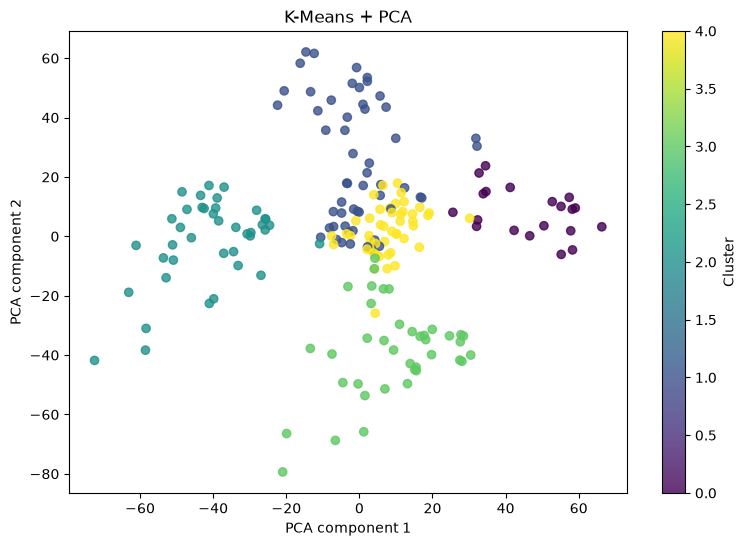

In [106]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    c=labels,
    alpha=0.8
)

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("K-Means + PCA")
plt.colorbar(scatter, label="Cluster")
plt.show()

По первым 2 компонентам достаточно нелпохо получается разделить категории покупателей :) Где-то overlapping, но не критично

# Выводы
Мне было интересно проверить PCA через SVD в этом случае, потому что PCA чаще используется для большого количества фичей, а здесь их всего три.
Эксперимент показал, как уменьшение размерности может использоваться для визуализации структуры данных и кластеров. При этом полученные результаты не доказывают, что PCA улучшает качество кластеризации: для такого вывода необходимо сопоставимо оценить обе модели. В данном случае основной практический результат PCA — получение более компактного представления данных для визуального анализа.

In [111]:
# Оцениваем ОБЕ разметки в одном пространстве: X_scaled
score_original = silhouette_score(X_scaled, labels_original)
score_svd_common = silhouette_score(X_scaled, labels_svd)

In [112]:
print(f"Исходные признаки: {score_original:.3f}")
print(f"После SVD, оценка в исходном пространстве: {score_svd_common:.3f}")

Исходные признаки: 0.417
После SVD, оценка в исходном пространстве: 0.326


Первоначальный эксперимент показал увеличение silhouette score с 0.417 до 0.553 после сокращения размерности до двух компонент. Однако при сопоставимой оценке в исходном пространстве результат после SVD составил 0.326 против 0.417 у исходной модели.

# Таким образом, эксперимент не подтвердил улучшение качества кластеризации после PCA. При этом метод позволил сократить размерность данных и визуализировать структуру кластеров.